In [ ]:
pip install keras-hub

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.metrics import accuracy_score

from tensorflow import keras
from tensorflow.keras import layers, activations, optimizers, losses, callbacks

from tensorflow.keras.layers import Input, Conv2D, BatchNormalization, Dropout, MaxPool2D, SimpleRNN, \
    LSTM, GRU, Flatten, GlobalAveragePooling2D, Dense, PReLU, Concatenate, Add, AveragePooling2D, Embedding

import keras_hub
from tensorflow.keras.preprocessing.text import  Tokenizer
from tensorflow.keras.preprocessing.sequence import  pad_sequences
import re

In [ ]:
df = pd.read_csv('/data/news_dataset.csv')

In [ ]:
df.head()

,title,text,subject,date,label
0,WATCH: Trump Just Told All The Anti-Gay Bigot...,A whole lot of evangelical Trump voters just d...,News,"November 13, 2016",0
1,"China backs U.N. call for justice in Yemen, U....",GENEVA (Reuters) - China signaled on Wednesday...,worldnews,"September 13, 2017",1
2,THE PEOPLE’S PRESIDENT: Trump Meets With Coal ...,,politics,"Feb 16, 2017",0
3,WSJ REPORTER RIPS INTO DEM CANDIDATES For Thei...,THE WSJ S MARY KISSEL NAILS IT ON THE DEM DEBA...,politics,"Nov 15, 2015",0
4,Lawmakers aim to delay U.S. ceding control of ...,WASHINGTON (Reuters) - Critics of a plan for t...,politicsNews,"September 13, 2016",1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    6000 non-null   object
 1   text     6000 non-null   object
 2   subject  6000 non-null   object
 3   date     6000 non-null   object
 4   label    6000 non-null   int64 
dtypes: int64(1), object(4)
memory usage: 234.5+ KB


In [ ]:
df['clean_title'] = [re.sub(r'[\n\t]', '', x.lower().strip()) for x in df['title']]
df['clean_text'] = [re.sub(r'[\n\t]', '', x.lower().strip()) for x in df['text']]
df['clean_subject'] = [re.sub(r'[\n\t]', '', x.lower().strip()) for x in df['subject']]
df['clean_date'] = [re.sub(r'[\n\t]', '', x.lower().strip()) for x in df['date']]

In [ ]:
df.head()

,title,text,subject,date,label,clean_title,clean_text,clean_subject,clean_date
0,WATCH: Trump Just Told All The Anti-Gay Bigot...,A whole lot of evangelical Trump voters just d...,News,"November 13, 2016",0,watch: trump just told all the anti-gay bigots...,a whole lot of evangelical trump voters just d...,news,"november 13, 2016"
1,"China backs U.N. call for justice in Yemen, U....",GENEVA (Reuters) - China signaled on Wednesday...,worldnews,"September 13, 2017",1,"china backs u.n. call for justice in yemen, u....",geneva (reuters) - china signaled on wednesday...,worldnews,"september 13, 2017"
2,THE PEOPLE’S PRESIDENT: Trump Meets With Coal ...,,politics,"Feb 16, 2017",0,the people’s president: trump meets with coal ...,,politics,"feb 16, 2017"
3,WSJ REPORTER RIPS INTO DEM CANDIDATES For Thei...,THE WSJ S MARY KISSEL NAILS IT ON THE DEM DEBA...,politics,"Nov 15, 2015",0,wsj reporter rips into dem candidates for thei...,the wsj s mary kissel nails it on the dem deba...,politics,"nov 15, 2015"
4,Lawmakers aim to delay U.S. ceding control of ...,WASHINGTON (Reuters) - Critics of a plan for t...,politicsNews,"September 13, 2016",1,lawmakers aim to delay u.s. ceding control of ...,washington (reuters) - critics of a plan for t...,politicsnews,"september 13, 2016"


In [ ]:
df = df.drop(columns=['title' , 'text' , 'subject' , 'date'])

In [ ]:
df.head()

,label,clean_title,clean_text,clean_subject,clean_date
0,0,watch: trump just told all the anti-gay bigots...,a whole lot of evangelical trump voters just d...,news,"november 13, 2016"
1,1,"china backs u.n. call for justice in yemen, u....",geneva (reuters) - china signaled on wednesday...,worldnews,"september 13, 2017"
2,0,the people’s president: trump meets with coal ...,,politics,"feb 16, 2017"
3,0,wsj reporter rips into dem candidates for thei...,the wsj s mary kissel nails it on the dem deba...,politics,"nov 15, 2015"
4,1,lawmakers aim to delay u.s. ceding control of ...,washington (reuters) - critics of a plan for t...,politicsnews,"september 13, 2016"


In [ ]:
X = df.drop(columns=['label'])
y = df['label']

In [ ]:
X_train_df, X_test_df, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state= 1)
print("X_train_df and X_test_df have been created as DataFrames.")

X_train_df and X_test_df have been created as DataFrames.


In [ ]:
tk = Tokenizer()

In [ ]:
X_train_combined = X_train_df['clean_title'] + ' ' + X_train_df['clean_text'] + ' ' + X_train_df['clean_subject'] + ' ' + X_train_df['clean_date']
tk.fit_on_texts(X_train_combined)
len(tk.word_index)

51934

In [ ]:
vocab_size = len(tk.word_index)
tk = Tokenizer(num_words = vocab_size)
tk.fit_on_texts(X_train_combined)

In [ ]:
X_train_combined = X_train_df['clean_title'] + ' ' + X_train_df['clean_text'] + ' ' + X_train_df['clean_subject'] + ' ' + X_train_df['clean_date']
X_test_combined = X_test_df['clean_title'] + ' ' + X_test_df['clean_text'] + ' ' + X_test_df['clean_subject'] + ' ' + X_test_df['clean_date']

X_train_sequences = tk.texts_to_sequences(X_train_combined)
X_test_sequences = tk.texts_to_sequences(X_test_combined)

In [ ]:
ls = []
for i in range(len(X_train_sequences)):
  ls.append(len(X_train_sequences[i]))

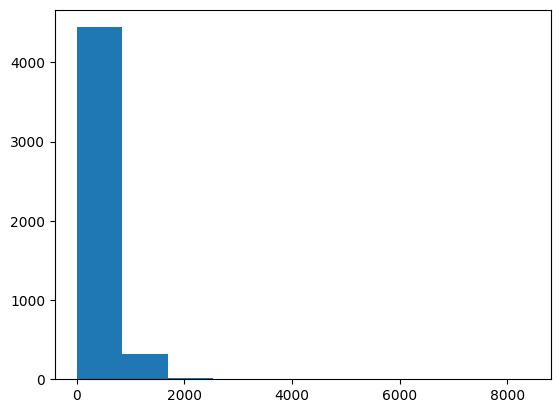

In [ ]:
plt.hist(ls, bins = 10)
plt.show()

In [ ]:
np.unique_counts(y)

UniqueCountsResult(values=array([0, 1]), counts=array([3000, 3000]))

In [ ]:
X_train = pad_sequences(X_train_sequences, maxlen= 995, padding='post')
X_test = pad_sequences(X_test_sequences, maxlen= 995, padding='post')

In [ ]:
input_layer = Input(shape = X_train.shape[1:])
emb1  = Embedding(input_dim=vocab_size + 1, output_dim=32)(input)
lstm1  = layers.Bidirectional(LSTM(64, return_sequences=True))(emb1)
lstm2  = LSTM(32, dropout=0.2)(lstm1)

fc1    = Dense(32, activation='relu')(lstm2)
dr1    = Dropout(0.2)(fc1)

output = Dense(2, activation='softmax')(dr1)

model = keras.Model(input, output)
model.summary()

adam = optimizers.Adam(learning_rate=0.004)
scce = losses.SparseCategoricalCrossentropy()

model.compile(
    optimizer=adam,
    loss=scce,
    metrics=['accuracy']
)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 995)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 995, 32)        │     1,661,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 995, 128)       │        49,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        20,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,733,314 (6.61 MB)

 Trainable params: 1,733,314 (6.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
es = callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
rlr = callbacks.ReduceLROnPlateau(monitor='val_loss', patience=5, factor=0.5)

history = model.fit(
    X_train, y_train,
    validation_split = 0.2,
    epochs = 5,
    batch_size=32,
    callbacks = [es, rlr]
)

Epoch 1/5
120/120 ━━━━━━━━━━━━━━━━━━━━ 12s 97ms/step - accuracy: 0.5221 - loss: 0.6652 - val_accuracy: 0.5354 - val_loss: 0.6639 - learning_rate: 0.0040
Epoch 2/5
120/120 ━━━━━━━━━━━━━━━━━━━━ 11s 95ms/step - accuracy: 0.5120 - loss: 0.6645 - val_accuracy: 0.5063 - val_loss: 0.6639 - learning_rate: 0.0040
Epoch 3/5
120/120 ━━━━━━━━━━━━━━━━━━━━ 11s 93ms/step - accuracy: 0.6448 - loss: 0.5807 - val_accuracy: 0.5396 - val_loss: 0.6889 - learning_rate: 0.0040


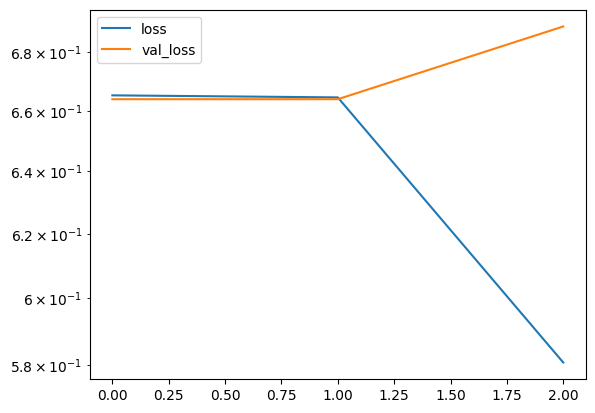

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.legend(['loss', 'val_loss'])
plt.yscale('log')

In [ ]:
y_pred = model.predict(X_test)
accuracy_score(y_test, np.argmax(y_pred, axis=1))

38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step


0.49083333333333334

In [ ]:
model_0_0 = keras_hub.models.AlbertClassifier.from_preset(
    "albert_base_en_uncased",
    num_classes=2,
)

model_0_0.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=keras.optimizers.Adam(5e-5),
    jit_compile=True,
)

100%|██████████| 44.6M/44.6M [00:01<00:00, 37.1MB/s]


100%|██████████| 596/596 [00:00<00:00, 1.42MB/s]


100%|██████████| 742k/742k [00:00<00:00, 2.08MB/s]


In [ ]:
model_0_0.summary()

Preprocessor: "albert_text_classifier_preprocessor_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                                  ┃                                   Config ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ albert_tokenizer (AlbertTokenizer)                            │                       Vocab size: 30,000 │
└───────────────────────────────────────────────────────────────┴──────────────────────────────────────────┘

Model: "albert_text_classifier_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ padding_mask (InputLayer)     │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ segment_ids (InputLayer)      │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ token_ids (InputLayer)        │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ albert_backbone               │ [(None, 768), (None,      │      11,683,584 │ padding_mask[0][0],        │
│ (AlbertBackbone)              │ None, 768)]               │                 │ segment_ids[0][0],         │
│                               │                           │                 │ token_ids[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ output_dropout (Dropout)      │ (None, 768)               │               0 │ albert_backbone[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ logits (Dense)                │ (None, 2)                 │           1,538 │ output_dropout[0][0]       │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 11,685,122 (44.58 MB)

 Trainable params: 11,685,122 (44.58 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model_0_1 = keras_hub.models.BertClassifier.from_preset(
    "bert_tiny_en_uncased",
    num_classes=2,
)

model_0_1.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=keras.optimizers.Adam(5e-5),
    jit_compile=True,
)

100%|██████████| 454/454 [00:00<00:00, 863kB/s]


In [ ]:
model_0_1.summary()

Preprocessor: "bert_text_classifier_preprocessor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                                  ┃                                   Config ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ bert_tokenizer (BertTokenizer)                                │                       Vocab size: 30,522 │
└───────────────────────────────────────────────────────────────┴──────────────────────────────────────────┘

Model: "bert_text_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ padding_mask (InputLayer)     │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ segment_ids (InputLayer)      │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ token_ids (InputLayer)        │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bert_backbone (BertBackbone)  │ [(None, 128), (None,      │       4,385,920 │ padding_mask[0][0],        │
│                               │ None, 128)]               │                 │ segment_ids[0][0],         │
│                               │                           │                 │ token_ids[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ classifier_dropout (Dropout)  │ (None, 128)               │               0 │ bert_backbone[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ logits (Dense)                │ (None, 2)                 │             258 │ classifier_dropout[0][0]   │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 4,386,178 (16.73 MB)

 Trainable params: 4,386,178 (16.73 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model_0_2 = keras_hub.models.AlbertClassifier.from_preset(
    "albert_large_en_uncased",
    num_classes=2,
)

model_0_2.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=keras.optimizers.Adam(5e-5),
    jit_compile=True,
)
model_0_2.summary()

Preprocessor: "albert_text_classifier_preprocessor_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                                  ┃                                   Config ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ albert_tokenizer (AlbertTokenizer)                            │                       Vocab size: 30,000 │
└───────────────────────────────────────────────────────────────┴──────────────────────────────────────────┘

Model: "albert_text_classifier_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ padding_mask (InputLayer)     │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ segment_ids (InputLayer)      │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ token_ids (InputLayer)        │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ albert_backbone               │ [(None, 1024), (None,     │      17,683,968 │ padding_mask[0][0],        │
│ (AlbertBackbone)              │ None, 1024)]              │                 │ segment_ids[0][0],         │
│                               │                           │                 │ token_ids[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ output_dropout (Dropout)      │ (None, 1024)              │               0 │ albert_backbone[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ logits (Dense)                │ (None, 2)                 │           2,050 │ output_dropout[0][0]       │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 17,686,018 (67.47 MB)

 Trainable params: 17,686,018 (67.47 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model_0_3 = keras_hub.models.BertClassifier.from_preset(
    "bert_medium_en_uncased",
    num_classes=2,
)

model_0_3.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=keras.optimizers.Adam(5e-5),
    jit_compile=True,
)

model_0_3.summary()

100%|██████████| 455/455 [00:00<00:00, 1.41MB/s]


100%|██████████| 158M/158M [00:03<00:00, 43.4MB/s]


Preprocessor: "bert_text_classifier_preprocessor_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                                  ┃                                   Config ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ bert_tokenizer (BertTokenizer)                                │                       Vocab size: 30,522 │
└───────────────────────────────────────────────────────────────┴──────────────────────────────────────────┘

Model: "bert_text_classifier_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ padding_mask (InputLayer)     │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ segment_ids (InputLayer)      │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ token_ids (InputLayer)        │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bert_backbone (BertBackbone)  │ [(None, 512), (None,      │      41,373,184 │ padding_mask[0][0],        │
│                               │ None, 512)]               │                 │ segment_ids[0][0],         │
│                               │                           │                 │ token_ids[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ classifier_dropout (Dropout)  │ (None, 512)               │               0 │ bert_backbone[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ logits (Dense)                │ (None, 2)                 │           1,026 │ classifier_dropout[0][0]   │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 41,374,210 (157.83 MB)

 Trainable params: 41,374,210 (157.83 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
es = callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
rlr = callbacks.ReduceLROnPlateau(monitor='val_loss', patience=5, factor=0.5)

history = model_0_0.fit(
    X_train_combined, y_train,
    validation_split = 0.2,
    epochs = 5,
    batch_size=2,
    callbacks = [es, rlr]
)

Epoch 1/5
1920/1920 ━━━━━━━━━━━━━━━━━━━━ 458s 219ms/step - loss: 0.2467 - sparse_categorical_accuracy: 0.8687 - val_loss: 0.6929 - val_sparse_categorical_accuracy: 0.5177 - learning_rate: 5.0000e-05
Epoch 2/5
1920/1920 ━━━━━━━━━━━━━━━━━━━━ 406s 211ms/step - loss: 0.7081 - sparse_categorical_accuracy: 0.4990 - val_loss: 0.7029 - val_sparse_categorical_accuracy: 0.4823 - learning_rate: 5.0000e-05
Epoch 3/5
1920/1920 ━━━━━━━━━━━━━━━━━━━━ 407s 212ms/step - loss: 0.7083 - sparse_categorical_accuracy: 0.4880 - val_loss: 0.7040 - val_sparse_categorical_accuracy: 0.4823 - learning_rate: 5.0000e-05


In [ ]:
es = callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
rlr = callbacks.ReduceLROnPlateau(monitor='val_loss', patience=5, factor=0.5)

history = model_0_1.fit(
    X_train_combined, y_train,
    validation_split = 0.2,
    epochs = 5,
    batch_size=2,
    callbacks = [es, rlr]
)

Epoch 1/5
1920/1920 ━━━━━━━━━━━━━━━━━━━━ 38s 11ms/step - loss: 0.1287 - sparse_categorical_accuracy: 0.9617 - val_loss: 0.0255 - val_sparse_categorical_accuracy: 0.9958 - learning_rate: 5.0000e-05
Epoch 2/5
1920/1920 ━━━━━━━━━━━━━━━━━━━━ 18s 9ms/step - loss: 0.0153 - sparse_categorical_accuracy: 0.9953 - val_loss: 0.0123 - val_sparse_categorical_accuracy: 0.9979 - learning_rate: 5.0000e-05
Epoch 3/5
1920/1920 ━━━━━━━━━━━━━━━━━━━━ 17s 9ms/step - loss: 0.0025 - sparse_categorical_accuracy: 0.9995 - val_loss: 0.0279 - val_sparse_categorical_accuracy: 0.9958 - learning_rate: 5.0000e-05
Epoch 4/5
1920/1920 ━━━━━━━━━━━━━━━━━━━━ 18s 9ms/step - loss: 0.0086 - sparse_categorical_accuracy: 0.9984 - val_loss: 0.0168 - val_sparse_categorical_accuracy: 0.9969 - learning_rate: 5.0000e-05


In [ ]:
es = callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
rlr = callbacks.ReduceLROnPlateau(monitor='val_loss', patience=5, factor=0.5)

history = model_0_2.fit(
    X_train_combined, y_train,
    validation_split = 0.2,
    epochs = 5,
    batch_size=2,
    callbacks = [es, rlr]
)

Epoch 1/5
1920/1920 ━━━━━━━━━━━━━━━━━━━━ 1274s 663ms/step - loss: 0.7142 - sparse_categorical_accuracy: 0.4846 - val_loss: 0.7088 - val_sparse_categorical_accuracy: 0.4823 - learning_rate: 5.0000e-05
Epoch 2/5
1920/1920 ━━━━━━━━━━━━━━━━━━━━ 1272s 663ms/step - loss: 0.7116 - sparse_categorical_accuracy: 0.4872 - val_loss: 0.7043 - val_sparse_categorical_accuracy: 0.4823 - learning_rate: 5.0000e-05
Epoch 3/5
1920/1920 ━━━━━━━━━━━━━━━━━━━━ 1269s 661ms/step - loss: 0.7072 - sparse_categorical_accuracy: 0.5010 - val_loss: 0.7031 - val_sparse_categorical_accuracy: 0.4823 - learning_rate: 5.0000e-05
Epoch 4/5
1920/1920 ━━━━━━━━━━━━━━━━━━━━ 1265s 659ms/step - loss: 0.7102 - sparse_categorical_accuracy: 0.4898 - val_loss: 0.7049 - val_sparse_categorical_accuracy: 0.4823 - learning_rate: 5.0000e-05
Epoch 5/5
1920/1920 ━━━━━━━━━━━━━━━━━━━━ 1248s 650ms/step - loss: 0.7136 - sparse_categorical_accuracy: 0.5034 - val_loss: 0.7043 - val_sparse_categorical_accuracy: 0.4823 - learning_rate: 5.0000e-05


In [ ]:
es = callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
rlr = callbacks.ReduceLROnPlateau(monitor='val_loss', patience=5, factor=0.5)

history = model_0_3.fit(
    X_train_combined, y_train,
    validation_split = 0.2,
    epochs = 5,
    batch_size=2,
    callbacks = [es, rlr]
)

Epoch 1/5
1920/1920 ━━━━━━━━━━━━━━━━━━━━ 207s 83ms/step - loss: 0.0535 - sparse_categorical_accuracy: 0.9823 - val_loss: 0.0062 - val_sparse_categorical_accuracy: 0.9969 - learning_rate: 5.0000e-05
Epoch 2/5
1920/1920 ━━━━━━━━━━━━━━━━━━━━ 162s 84ms/step - loss: 0.0233 - sparse_categorical_accuracy: 0.9932 - val_loss: 0.0051 - val_sparse_categorical_accuracy: 0.9990 - learning_rate: 5.0000e-05
Epoch 3/5
1920/1920 ━━━━━━━━━━━━━━━━━━━━ 163s 85ms/step - loss: 0.0837 - sparse_categorical_accuracy: 0.9740 - val_loss: 0.0238 - val_sparse_categorical_accuracy: 0.9969 - learning_rate: 5.0000e-05
Epoch 4/5
1920/1920 ━━━━━━━━━━━━━━━━━━━━ 163s 85ms/step - loss: 0.0886 - sparse_categorical_accuracy: 0.9630 - val_loss: 0.0610 - val_sparse_categorical_accuracy: 0.9885 - learning_rate: 5.0000e-05


In [ ]:
y_pred = model_0_0.predict(X_test_combined)
accuracy_score(y_test, np.argmax(y_pred, axis=1))

38/38 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step


0.48

In [ ]:
y_pred = model_0_1.predict(X_test_combined)
accuracy_score(y_test, np.argmax(y_pred, axis=1))

38/38 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step


0.9991666666666666

In [ ]:
y_pred = model_0_2.predict(X_test_combined)
accuracy_score(y_test, np.argmax(y_pred, axis=1))

38/38 ━━━━━━━━━━━━━━━━━━━━ 137s 3s/step


0.52

In [ ]:
y_pred = model_0_3.predict(X_test_combined)
accuracy_score(y_test, np.argmax(y_pred, axis=1))

38/38 ━━━━━━━━━━━━━━━━━━━━ 21s 449ms/step


0.9975